# Lab 10 Image Segmentation and Feature Extraction

## Setup

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage import data

plt.rcParams.update({'figure.dpi': 110, 'font.size': 10})
print('OpenCV:', cv2.__version__)

OpenCV: 5.0.0


## Task 1 Canny Edge Detection

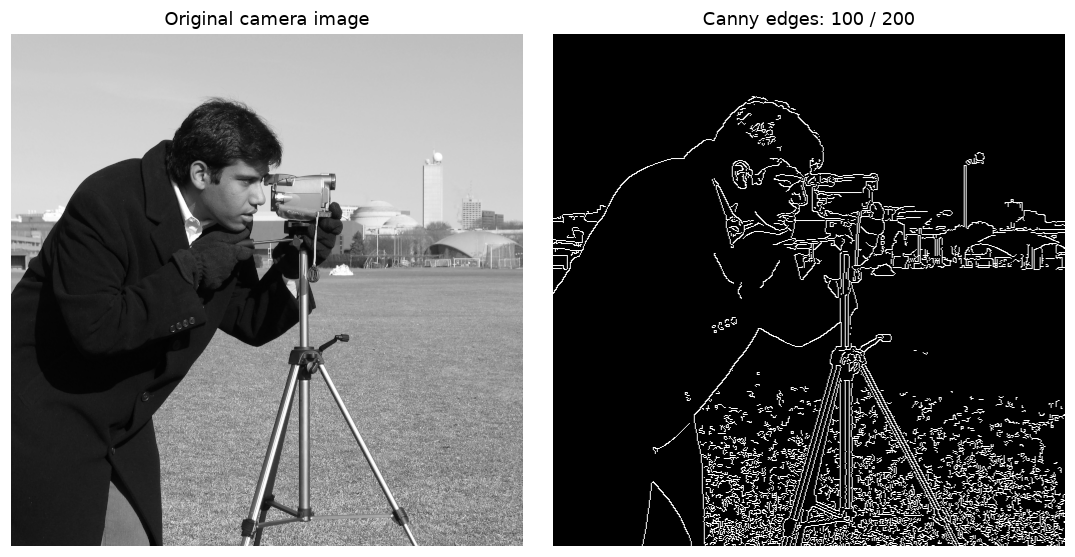

Edge pixels: 19686


In [2]:
camera = data.camera()
edges = cv2.Canny(camera, 100, 200)
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
for ax, title, image in zip(axes, ['Original camera image', 'Canny edges: 100 / 200'], [camera, edges]):
    ax.imshow(image, cmap='gray', vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis('off')
fig.tight_layout()
plt.show()
print('Edge pixels:', np.count_nonzero(edges))

## Task 2 Harris Corner Detection

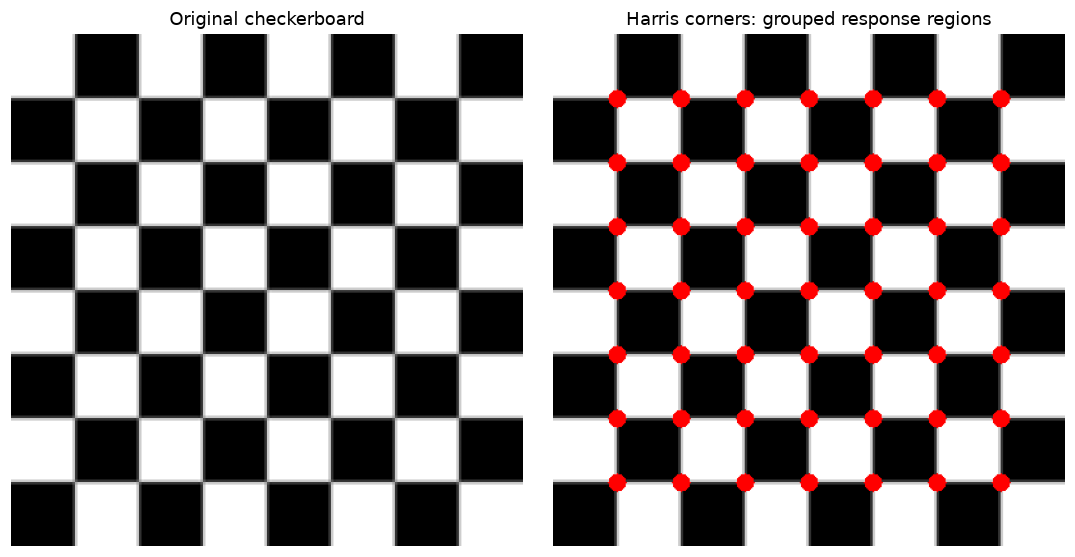

Connected corner-response regions: 49


In [3]:
board = data.checkerboard()
board = cv2.resize(board, (400, 400), interpolation=cv2.INTER_NEAREST)
image = cv2.cvtColor(board, cv2.COLOR_GRAY2BGR)
gray = board.astype(np.float32)
harris_raw = cv2.cornerHarris(gray, blockSize=2, ksize=3, k=0.04)
harris = cv2.dilate(harris_raw, None)
corner_threshold = 0.01 * harris.max()
corner_mask = (harris > corner_threshold).astype(np.uint8)
component_count, labels, stats, centroids = cv2.connectedComponentsWithStats(corner_mask, connectivity=8)
corner_centers = centroids[1:]
for x, y in corner_centers:
    cv2.circle(image, (int(round(x)), int(round(y))), radius=7, color=(0, 0, 255), thickness=-1)
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(board, cmap='gray', vmin=0, vmax=255)
axes[0].set_title('Original checkerboard')
axes[1].imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
axes[1].set_title('Harris corners: grouped response regions')
for ax in axes:
    ax.axis('off')
fig.tight_layout()
plt.show()
print('Connected corner-response regions:', len(corner_centers))

## Simple Global Binary Thresholding

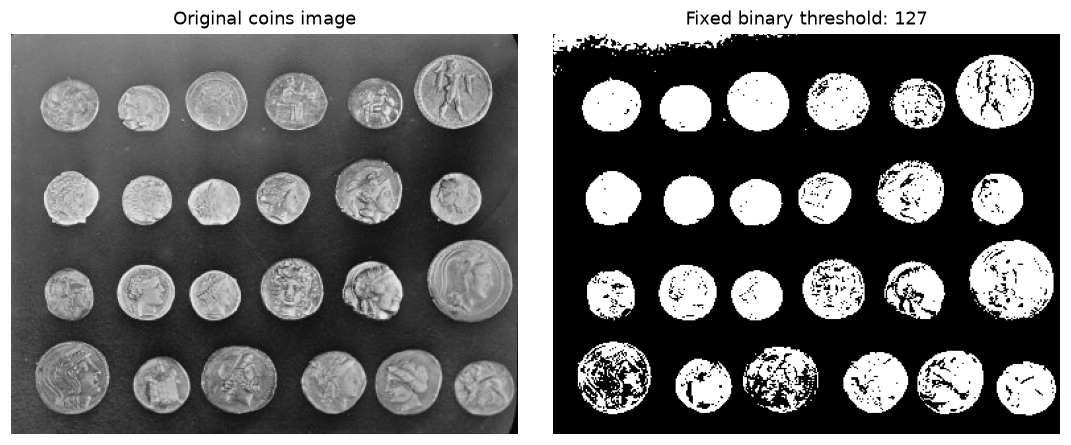

In [4]:
coins = data.coins()
fixed_threshold = 127
_, fixed_binary = cv2.threshold(coins, fixed_threshold, 255, cv2.THRESH_BINARY)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, title, result in zip(axes, ['Original coins image', 'Fixed binary threshold: 127'], [coins, fixed_binary]):
    ax.imshow(result, cmap='gray', vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis('off')
fig.tight_layout()
plt.show()

## Q1 Otsu's Thresholding

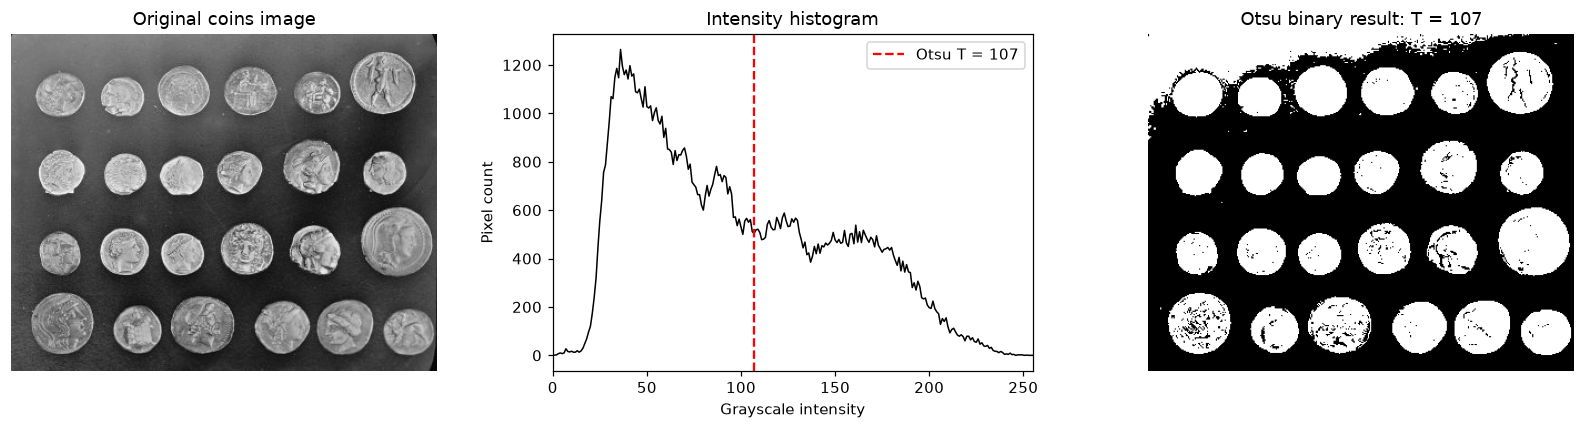

Automatic Otsu threshold: 107
White pixels: 45,117 (38.78%)
Pixels above the threshold are white; the rest are black.


In [5]:
otsu_threshold, otsu_binary = cv2.threshold(coins, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
histogram = np.bincount(coins.ravel(), minlength=256)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].imshow(coins, cmap='gray', vmin=0, vmax=255)
axes[0].set_title('Original coins image')
axes[0].axis('off')
axes[1].plot(np.arange(256), histogram, color='black', linewidth=1)
axes[1].axvline(otsu_threshold, color='red', linestyle='--', label=f'Otsu T = {otsu_threshold:.0f}')
axes[1].set_xlim(0, 255)
axes[1].set_xlabel('Grayscale intensity')
axes[1].set_ylabel('Pixel count')
axes[1].set_title('Intensity histogram')
axes[1].legend()
axes[2].imshow(otsu_binary, cmap='gray', vmin=0, vmax=255)
axes[2].set_title(f'Otsu binary result: T = {otsu_threshold:.0f}')
axes[2].axis('off')
fig.tight_layout()
plt.show()
print(f'Automatic Otsu threshold: {otsu_threshold:.0f}')
print(f'White pixels: {np.count_nonzero(otsu_binary):,} ({100 * np.count_nonzero(otsu_binary) / otsu_binary.size:.2f}%)')
print('Pixels above the threshold are white; the rest are black.')

### Q1 Brief Answer

Otsu chooses the threshold that maximizes between-class variance. It separates brighter coin regions from darker background, but uneven illumination can leave imperfect boundaries.

## Verification

In [6]:
assert camera.dtype == np.uint8 and coins.dtype == np.uint8
assert edges.shape == camera.shape
assert fixed_binary.shape == coins.shape == otsu_binary.shape
for binary in [edges, fixed_binary, otsu_binary]:
    assert binary.dtype == np.uint8
    assert set(np.unique(binary)).issubset({0, 255})
assert np.array_equal(fixed_binary, (coins > fixed_threshold).astype(np.uint8) * 255)
assert np.array_equal(otsu_binary, (coins > otsu_threshold).astype(np.uint8) * 255)
assert int(histogram.sum()) == coins.size
assert len(corner_centers) > 0 and np.isfinite(harris_raw).all()
probabilities = histogram.astype(np.float64) / coins.size
class_weight = np.cumsum(probabilities)
class_moment = np.cumsum(probabilities * np.arange(256))
total_mean = class_moment[-1]
between_variance = np.full(256, -np.inf)
valid = (class_weight > 0) & (class_weight < 1)
between_variance[valid] = (total_mean * class_weight[valid] - class_moment[valid]) ** 2 / (class_weight[valid] * (1 - class_weight[valid]))
independent_threshold = int(np.argmax(between_variance))
assert int(otsu_threshold) == independent_threshold
assert np.isfinite(between_variance[valid]).all()
print('Independent Otsu calculation:', independent_threshold)
print('All image, binary mask, histogram, corner and Otsu checks passed.')

Independent Otsu calculation: 107
All image, binary mask, histogram, corner and Otsu checks passed.
